# IMACEC de Industria en Chile — análisis de serie de tiempo con R

**Serie:** Imacec industria, serie original, índice con promedio 2018 = 100.  
**Código de la serie:** `F032.IMC.IND.Z.Z.EP18.04.Z.0.M`  
**Fuente:** Banco Central de Chile, Base de Datos Estadísticos (archivo asignado).  
**Referencia de trabajo:** notebook `desocupacion_chile.ipynb` de la profesora.

**Para ejecutar en Google Colab:**
1. Abro este notebook con el entorno de ejecución R
2. En el panel lateral Archivos, subo `CCNN2018_IMACEC_01_A (Industria).xlsx`.
3. Entorno de ejecución → Ejecutar todas

## 1. Revisión de mi archivo antes de programar

**¿Cuál es la frecuencia?** La serie es **mensual** hay una observación por cada mes.

**¿En qué unidad está medida?** Está medida en un **índice (promedio 2018 = 100)**, no en una tasa porcentual. Un valor de 103,84 corresponde a puntos de índice y no significa que la industria esté creciendo un 103,84 %.

**¿Desde qué fecha hay datos?** La primera observación efectivamente disponible en la hoja `Cuadro` es enero de 2013 y la última es agosto de 2026. Son 164 observaciones mensuales consecutivas. Aunque la hoja `Metadatos` indica enero de 1996 como primera observación de la serie general, en el archivo asignado los datos parten en enero de 2013.

**Estructura del Excel:** la hoja a leer es **`Cuadro`**. La fila 1 contiene un título, la fila 2 está vacía y la fila 3 tiene los encabezados `Periodo` y `2.2. Industria`. Por eso uso **`skip = 2`** y selecciono las dos primeras columnas.

## 2. Paquetes y lectura del archivo

In [ ]:
# Colab (R) ya trea tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl)
  library(dplyr)
  library(ggplot2)
  library(scales)
  library(tidyr)
})

In [ ]:
#Lectura y limpieza de datos; Busco el archivo asignado pero antes de ejecutar, lo subo al panel de Colab.
archivo <- "CCNN2018_IMACEC_01_A (Industria).xlsx"
if (!file.exists(archivo)) archivo <- file.path("/content", basename(archivo))
if (!file.exists(archivo)) {
  stop("No encontré el Excel de Industria. Súbelo al panel de archivos de Colab y ejecuta de nuevo.")
}
cat("Archivo:", archivo, "\n")

# Verifico la hoja: Cuadro. Fila 3 = encabezados, por eso skip = 2.
print(excel_sheets(archivo))
raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)

# readxl suele reconocer las fechas de Excel; esta función también admite números de serie Excel si se importaron como números.
convertir_fecha <- function(x) {
  if (inherits(x, "Date")) return(x)
  if (inherits(x, "POSIXt")) return(as.Date(x))
  if (is.numeric(x)) return(as.Date(x, origin = "1899-12-30"))
  return(as.Date(x))
}

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(
    fecha = convertir_fecha(fecha),
    indice = as.numeric(indice)
  ) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha)

# Verifico que hay exactamente una observación para cada mes.
meses_esperados <- seq.Date(min(df$fecha), max(df$fecha), by = "month")
stopifnot(identical(meses_esperados, df$fecha))
cat("Observaciones:", nrow(df), "\n")
cat("Primera fecha:", as.character(min(df$fecha)), "\n")
cat("Última fecha:", as.character(max(df$fecha)), "\n")

# Resumen estadístico y últimas 6 observaciones que pide la profesora.
summary(df)
tail(df)

Archivo: CCNN2018_IMACEC_01_A (Industria).xlsx 
[1] "Cuadro"    "Metadatos" "Series"   
Observaciones: 164 
Primera fecha: 2013-01-01 
Última fecha: 2026-08-01 


     fecha                indice      
 Min.   :2013-01-01   Min.   : 82.26  
 1st Qu.:2016-05-24   1st Qu.: 93.78  
 Median :2019-10-16   Median : 98.56  
 Mean   :2019-10-16   Mean   : 98.79  
 3rd Qu.:2023-03-08   3rd Qu.:103.83  
 Max.   :2026-08-01   Max.   :116.44  

fecha,indice
<date>,<dbl>
2026-03-01,113.9593
2026-04-01,111.7409
2026-05-01,103.1825
2026-06-01,103.9028
2026-07-01,103.9749
2026-08-01,103.8445


## 3. Adaptación de los cálculos a Industria

Como mi variable es un índice, la variación en doce meses se calcula como una **tasa de crecimiento porcentual**: (valor / lag(valor, 12) - 1) * 100

La fórmula compara proporcionalmente el nivel del índice con el del mismo mes del año anterior. **No corresponde restar los valores y llamarlos puntos porcentuales**, porque eso solo es apropiado cuando la serie es una tasa expresada en porcentaje, como la desocupación. También calculo un **promedio móvil de 12 meses** del nivel del índice para suavizar los cambios de un mes a otro. Como hay datos mensuales sin meses faltantes, `lag(indice, 12)` corresponde al mismo mes del año anterior.

In [ ]:
# Variación interanual en % = crecimiento relativo respecto de hace 12 meses.
df <- df |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1 / 12, 12), sides = 1)),
    var_12m   = (indice / dplyr::lag(indice, 12) - 1) * 100
  )

# Reviso los cálculos del final de la serie.
tail(df, 6)

# Indicadores para comparar el último dato con todo el período.
ultimo   <- df |> slice_tail(n = 1)
maximo   <- df |> slice_max(indice, n = 1, with_ties = FALSE)
minimo   <- df |> slice_min(indice, n = 1, with_ties = FALSE)
promedio <- mean(df$indice)

cat("Promedio del período:", round(promedio, 2), "puntos de índice\n")
cat("Máximo:", round(maximo$indice, 2), "-", as.character(maximo$fecha), "\n")
cat("Mínimo:", round(minimo$indice, 2), "-", as.character(minimo$fecha), "\n")
cat("Último dato:", round(ultimo$indice, 2), "-", as.character(ultimo$fecha), "\n")
cat("Promedio móvil 12 meses:", round(ultimo$media_12m, 2), "puntos de índice\n")
cat("Variación en 12 meses:", round(ultimo$var_12m, 2), "%\n")

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2026-03-01,113.9593,2026,3,107.5254,-2.1296189
2026-04-01,111.7409,2026,4,107.6122,0.9409402
2026-05-01,103.1825,2026,5,107.4905,-1.3964385
2026-06-01,103.9028,2026,6,107.4383,-0.5982961
2026-07-01,103.9749,2026,7,107.1648,-3.0607520
2026-08-01,103.8445,2026,8,107.1879,0.2682544


Promedio del período: 98.79 puntos de índice
Máximo: 116.44 - 2025-03-01 
Mínimo: 82.26 - 2013-09-01 
Último dato: 103.84 - 2026-08-01 
Promedio móvil 12 meses: 107.19 puntos de índice
Variación en 12 meses: 0.27 %


## 4. Estilo común para los gráficos



In [ ]:
# Conservo el estilo del notebook original, pero cambio las unidades y la fuente.
meses_es <- c("Ene", "Feb", "Mar", "Abr", "May", "Jun",
              "Jul", "Ago", "Sep", "Oct", "Nov", "Dic")
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
num_es <- function(x) scales::number(x, accuracy = 0.01, decimal.mark = ",", big.mark = ".")

col_principal <- "#1F4E79"  # azul
col_acento    <- "#E07B39"  # naranjo

tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title          = element_text(face = "bold", size = 17, colour = "#1A1A1A"),
    plot.subtitle       = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption        = element_text(colour = "#777777", size = 9, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    panel.grid.minor    = element_blank(),
    panel.grid.major.x  = element_blank(),
    panel.grid.major.y  = element_line(colour = "#E5E5E5"),
    legend.position     = "top",
    legend.justification = "left",
    plot.background     = element_rect(fill = "white", colour = NA),
    plot.margin         = margin(15, 20, 10, 15)
  )

fuente <- paste0(
  "Fuente: Banco Central de Chile, Base de Datos Estadísticos. ",
  "Serie F032.IMC.IND.Z.Z.EP18.04.Z.0.M ",
  "(Imacec industria, serie original; índice promedio 2018=100)."
)

## 5. Gráfico 1: serie de Industria con promedio móvil

El gráfico muestra el nivel mensual del índice y su promedio móvil de 12 meses. Destaco el máximo, el mínimo y la observación más reciente; el período de 2020 está sombreado como referencia de la pandemia.

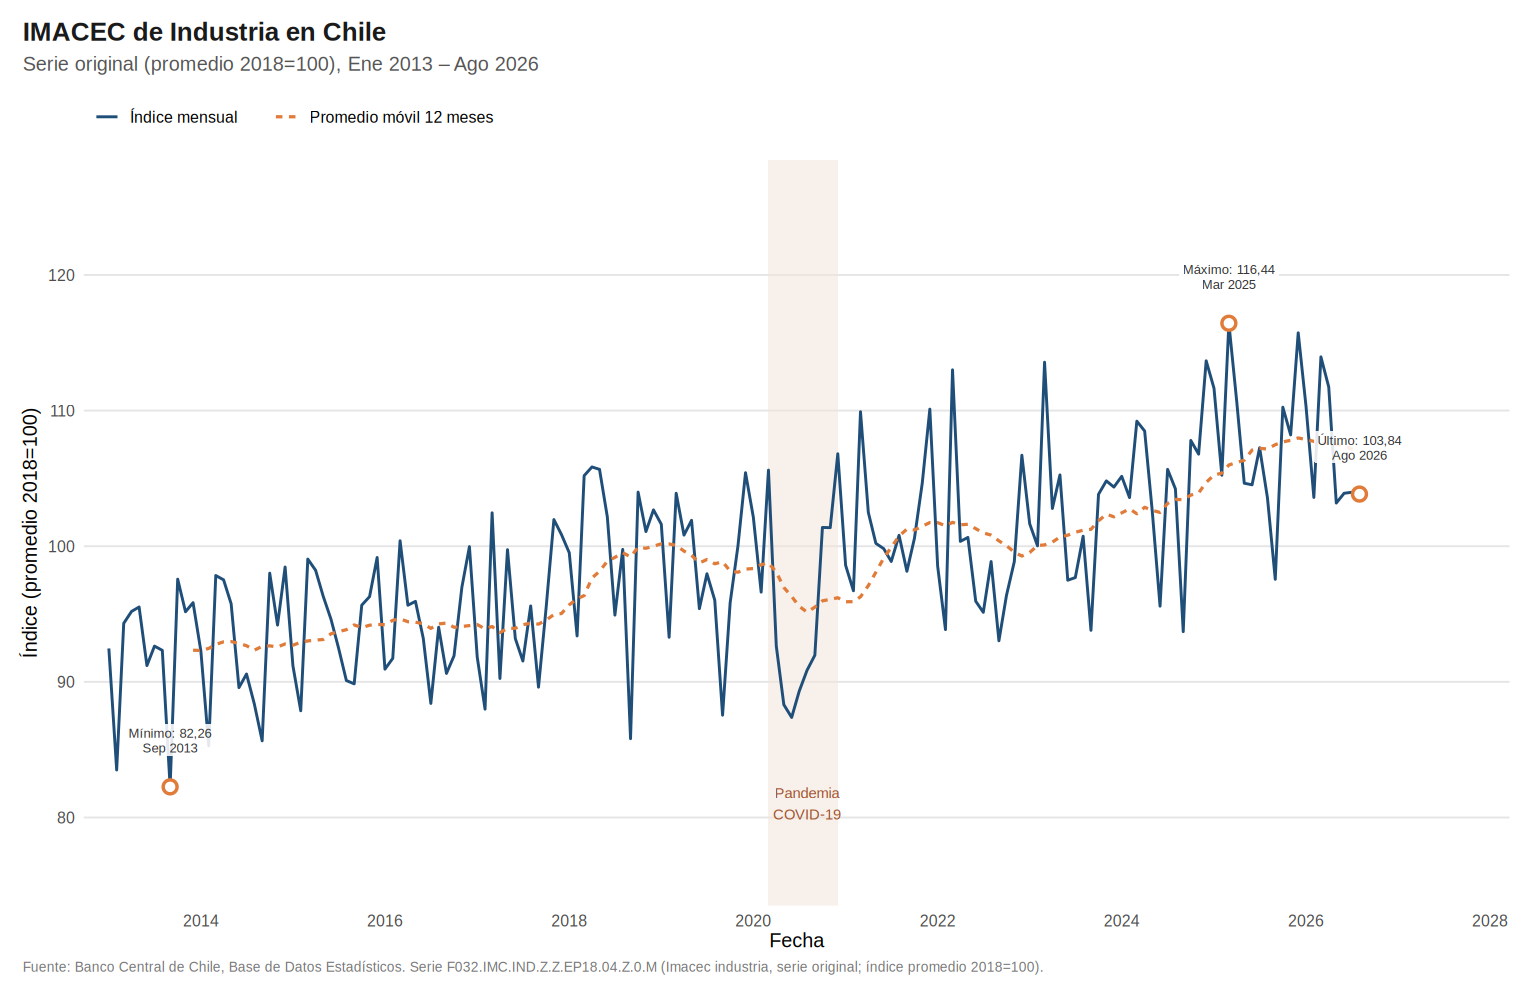

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 9, repr.plot.res = 110)

# Etiquetas destacadas: máximo, mínimo y último registro.
hitos <- bind_rows(
  maximo |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha))),
  minimo |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha))),
  ultimo |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)))
)

# Los límites del eje Y se calculan con los datos de Industria; no se usa el rango de tasas de desocupación.
y_min <- floor(min(df$indice) - 6)
y_max <- ceiling(max(df$indice) + 9)

g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2020-12-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = 0.55) +
  annotate("text", x = as.Date("2020-08-01"), y = y_min + 5,
           label = "Pandemia\nCOVID-19", size = 3.4, colour = "#A0522D") +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = 0.9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = 1.0, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3.2,
             colour = col_acento, fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = indice, label = txt),
             size = 3.0, nudge_y = 2.3, vjust = 0, linewidth = 0,
             fill = scales::alpha("white", 0.88), colour = "#333333", lineheight = 0.95) +
  scale_colour_manual(NULL,
                      values = c("Índice mensual" = col_principal,
                                 "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y",
               expand = expansion(mult = c(0.02, 0.12))) +
  scale_y_continuous(labels = scales::label_number(accuracy = 1),
                     limits = c(y_min, y_max)) +
  labs(title = "IMACEC de Industria en Chile",
       subtitle = paste0("Serie original (promedio 2018=100), ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = "Fecha", y = "Índice (promedio 2018=100)", caption = fuente) +
  tema

g1

## 6. Gráfico 2: mapa de calor

Comparo cada mes y cada año. Los colores indican niveles del índice (no porcentajes), y el contraste de los textos cambia según un umbral calculado a partir de la propia serie.

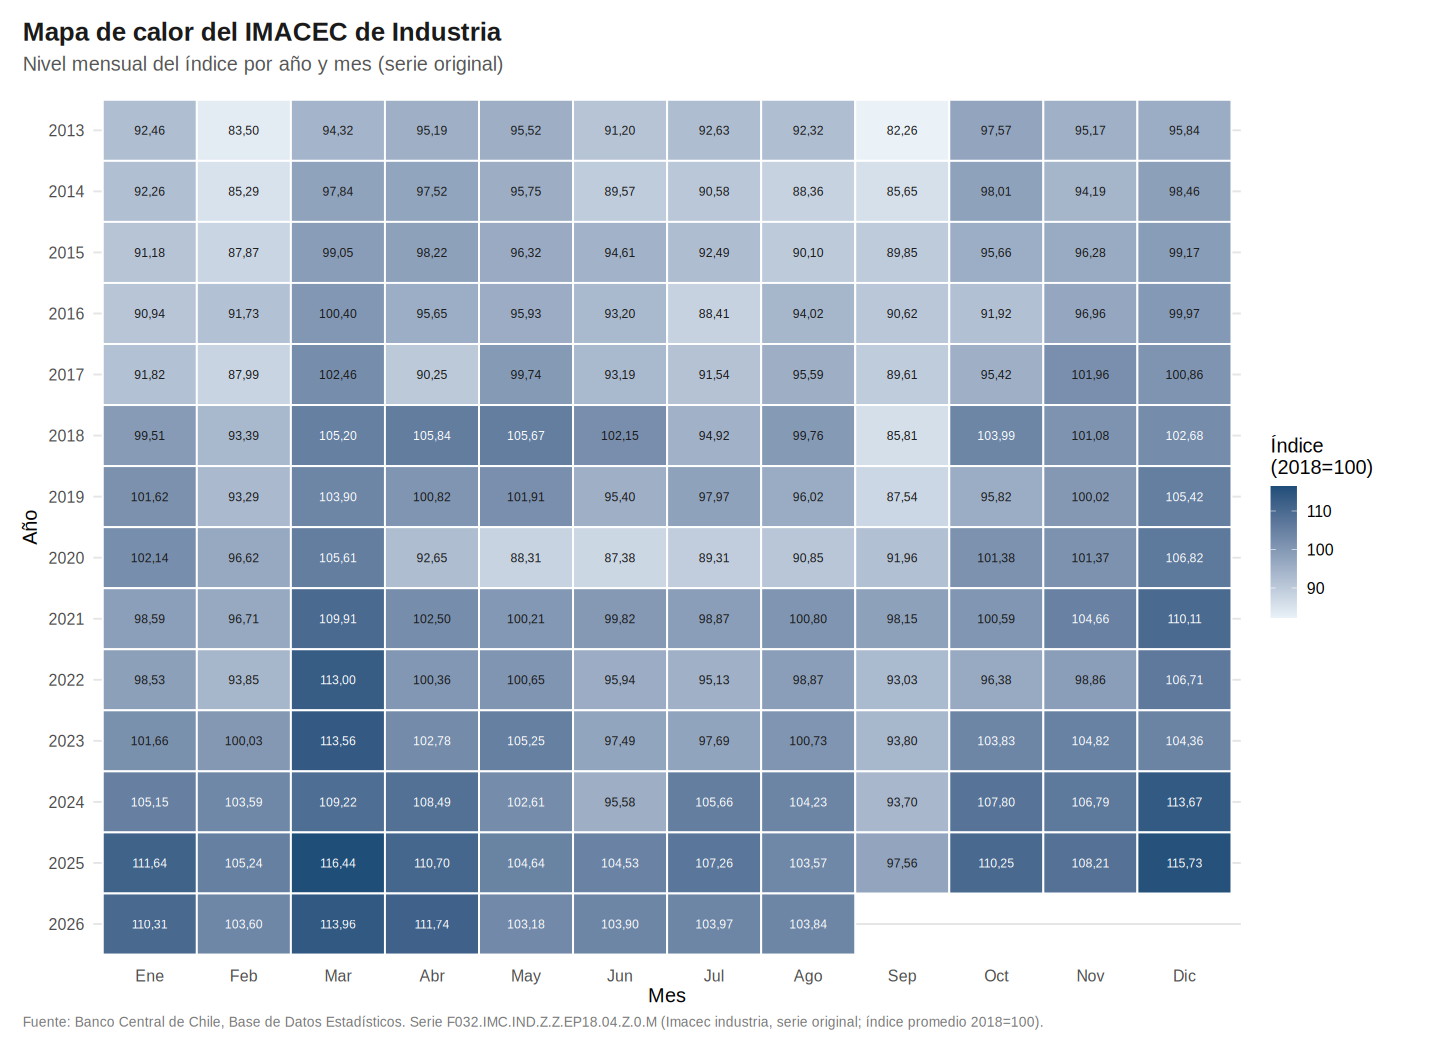

In [ ]:
options(repr.plot.width = 13, repr.plot.height = 9.5, repr.plot.res = 110)

# A diferencia del notebook de desocupación, aquí NO hay umbral de 10 %.
# Ajusto automáticamente el contraste del texto según el índice de Industria.
umbral_color <- as.numeric(quantile(df$indice, 0.70))

g2 <- ggplot(df,
             aes(factor(mes, levels = 1:12, labels = meses_es),
                 factor(anio, levels = rev(sort(unique(anio)))),
                 fill = indice)) +
  geom_tile(colour = "white", linewidth = 0.6) +
  geom_text(aes(label = num_es(indice), colour = indice > umbral_color),
            size = 2.8, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#EAF2F8", high = "#1F4E79",
                      name = "Índice\n(2018=100)") +
  labs(title = "Mapa de calor del IMACEC de Industria",
       subtitle = "Nivel mensual del índice por año y mes (serie original)",
       x = "Mes", y = "Año", caption = fuente) +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

## 7. Gráfico 3: variación en doce meses

Las barras representan **crecimiento o disminución porcentual** del índice respecto del mismo mes del año anterior. No son puntos porcentuales.

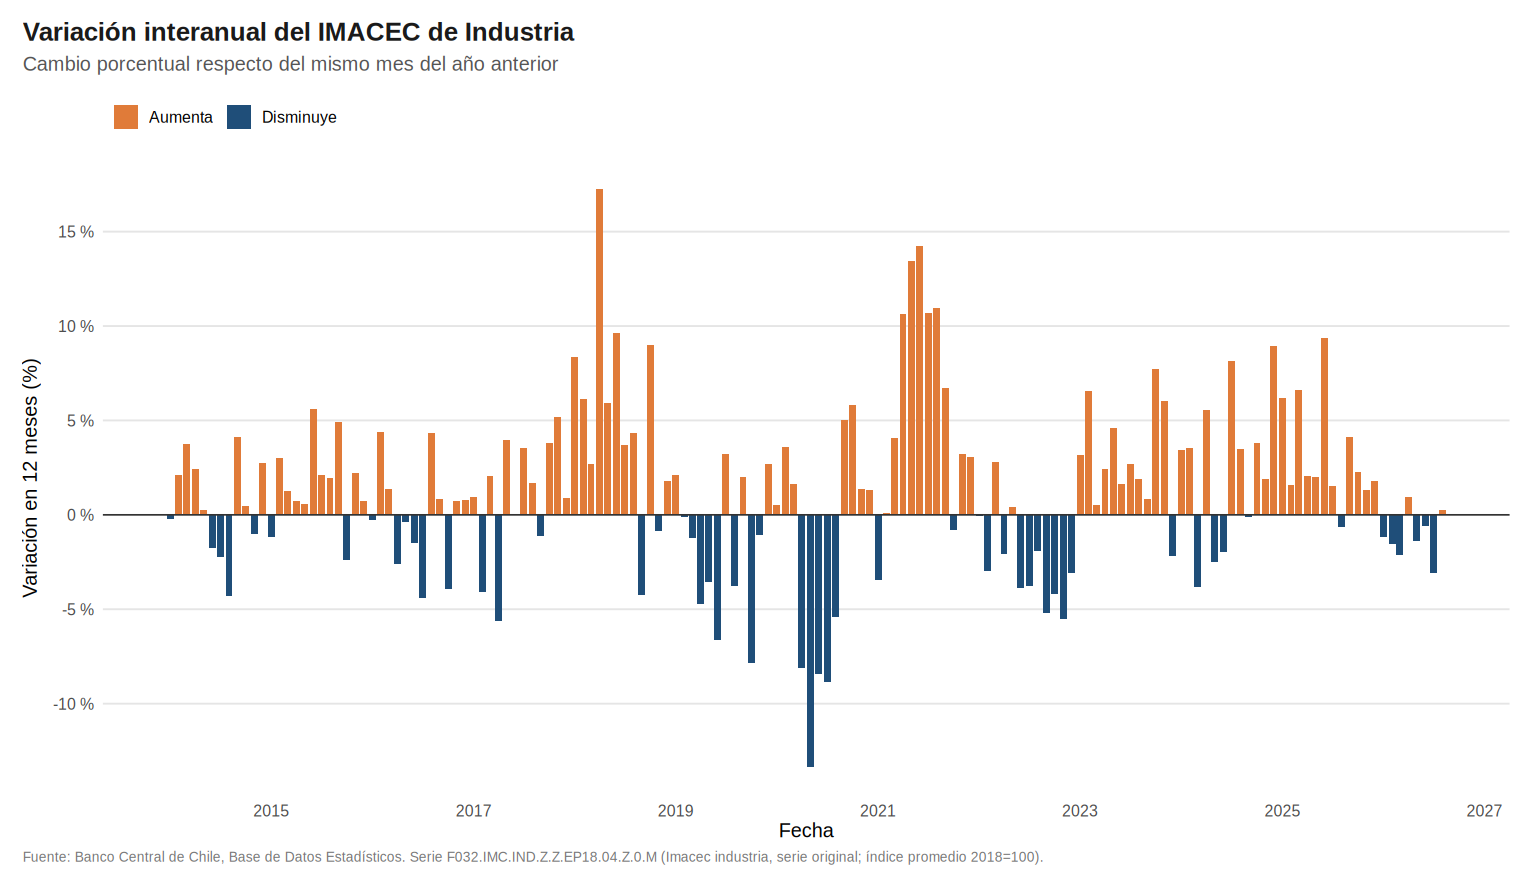

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 8, repr.plot.res = 110)

g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m >= 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333", linewidth = 0.5) +
  scale_fill_manual(NULL,
                    values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    breaks = c("TRUE", "FALSE"),
                    labels = c("Aumenta", "Disminuye")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(breaks = scales::breaks_pretty(n = 8),
                     labels = scales::label_number(accuracy = 1, suffix = " %")) +
  labs(title = "Variación interanual del IMACEC de Industria",
       subtitle = "Cambio porcentual respecto del mismo mes del año anterior",
       x = "Fecha", y = "Variación en 12 meses (%)", caption = fuente) +
  tema

g3

## 8. Interpretación económica (250–400 palabras)

Al analizar el IMACEC de Industria, observo que el dato más reciente corresponde a **agosto de 2026**, con **103,84 puntos de índice**. Este valor está por encima del promedio de **98,79 puntos** registrado entre enero de 2013 y agosto de 2026, con una diferencia de aproximadamente **5,05 puntos de índice**. Sin embargo, se encuentra por debajo del promedio móvil de los últimos doce meses, que llega a **107,19 puntos**. Esto indica que el nivel actual supera el promedio histórico de mi muestra, aunque es menor que el nivel medio más reciente.

El **máximo** de la serie ocurre en **marzo de 2025**, con **116,44 puntos**, mientras que el **mínimo** se registra en **septiembre de 2013**, con **82,26 puntos**. El bajo nivel de septiembre de 2013 podría estar influido por los feriados y el calendario laboral y para marzo de 2025 el Banco Central destacó una mayor producción manufacturera de alimentos y un día hábil adicional respecto del año anterior, factores que podrían contribuir al resultado alto. Son explicaciones posibles, no causas que el gráfico demuestre por sí solo. También se aprecia una baja durante 2020, consistente con las restricciones y dificultades productivas de la pandemia de COVID-19.

En el **mapa de calor** identifico un patrón que se repite en distintos años: **marzo y diciembre** tienden a mostrar niveles relativamente altos, mientras que **febrero y septiembre** suelen presentar valores más bajos. Esto sugiere estacionalidad y efectos de calendario, aunque necesitaría una serie desestacionalizada para separar mejor estos efectos de la tendencia económica.

Finalmente, la **variación en doce meses de agosto de 2026 es de aproximadamente +0,27 %** respecto de agosto de 2025. Por lo tanto, la actividad industrial muestra un crecimiento interanual muy leve en el último dato, más cercano al estancamiento que a una expansión fuerte. Esto demuestra que un nivel de índice superior al promedio histórico no implica necesariamente un crecimiento rápido en la actualidad.

**Fuentes de contexto económico (complementarias al Excel):** [Banco Central, Imacec marzo de 2025](https://www.bcentral.cl/contenido/-/details/imacec-marzo-2025); [Banco Central, efectos de calendario en la industria en septiembre (IPoM 2018)](https://www.bcentral.cl/documents/33528/3397397/recuadroIPoMDic2018III-1efecto.pdf/cc6064b1-6f18-9b47-bdf7-ce1710cdd164); [Banco Central, Imacec mayo de 2020](https://www.bcentral.cl/en/c/portal/update_language?languageId=es_ES&p_l_id=1652987&redirect=%2Fen%2Fweb%2Fbanco-central%2Fcontent%2F-%2Fdetails%2Fimacec-mayo-2020-1). Estas fuentes ayudan a contextualizar las fechas; los valores calculados provienen solo del archivo asignado.

## 9. Guardar los gráficos en PNG


In [ ]:
# Los PNG quedan guardados en /content y se pueden descargar desde Archivos.
ggsave("industria_serie.png", g1, width = 12, height = 6.5, dpi = 300)
ggsave("industria_mapa_calor.png", g2, width = 11, height = 8, dpi = 300)
ggsave("industria_variacion_12m.png", g3, width = 12, height = 6, dpi = 300)
list.files(pattern = "^industria_.*\\.png$")

[1] "industria_mapa_calor.png"    "industria_serie.png"        
[3] "industria_variacion_12m.png"